In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
import tensorflow as tf
from tensorflow import keras
import xgboost as xgb
from scipy.stats import norm

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)

In [2]:
DATA_DIR = '/content/drive/MyDrive/data_files/2021-2026'

OPTION_FILE = f"{DATA_DIR}/Nifty2021-2026.csv"
SPOT_FILE   = f"{DATA_DIR}/Nifty_Spot.csv"
BOND_FILE   = f"{DATA_DIR}/bond_yield.csv"

In [3]:
opt = pd.read_csv(OPTION_FILE)

opt = opt.drop(columns=['Unnamed: 0'], errors='ignore')
opt.columns = [
    'symbol', 'date', 'expiry', 'option_type', 'strike',
    'open', 'high', 'low', 'close', 'ltp', 'settle_price',
    'contracts', 'turnover_lakhs', 'premium_turnover_lakhs',
    'open_interest', 'change_in_oi', 'underlying'
]

opt['date']   = pd.to_datetime(opt['date'],   format='%d-%b-%Y', errors='coerce')
opt['expiry'] = pd.to_datetime(opt['expiry'], format='%d-%b-%Y', errors='coerce')

num_cols = ['strike', 'open', 'high', 'low', 'close', 'ltp', 'settle_price',
            'contracts', 'turnover_lakhs', 'premium_turnover_lakhs',
            'open_interest', 'change_in_oi', 'underlying']
for c in num_cols:
    opt[c] = pd.to_numeric(opt[c].astype(str).str.replace(',', ''), errors='coerce')

opt['option_type'] = opt['option_type'].str.strip().str.upper()
opt = opt[opt['option_type'] == 'CE']                       # European CALL options only
opt = opt.dropna(subset=['date', 'expiry', 'strike', 'underlying']).reset_index(drop=True)

print("Loaded option contract rows:", opt.shape)
opt.head()

/tmp/ipykernel_3440/1300781297.py:1: DtypeWarning: Columns (9,17) have mixed types. Specify dtype option on import or set low_memory=False.
  opt = pd.read_csv(OPTION_FILE)


Loaded option contract rows: (439497, 17)


,symbol,date,expiry,option_type,strike,open,high,low,close,ltp,settle_price,contracts,turnover_lakhs,premium_turnover_lakhs,open_interest,change_in_oi,underlying
0,NIFTY,2021-05-28,2021-06-10,CE,14700.0,733.75,733.75,730.00,730.00,730.0,821.80,2.0,23.15,1.10,225.0,NaN,15435.65
1,NIFTY,2021-05-28,2021-06-10,CE,15500.0,145.30,149.95,122.00,129.80,132.6,129.80,10980.0,128771.36,1128.86,231525.0,89475.0,15435.65
2,NIFTY,2021-05-28,2021-06-10,CE,16300.0,5.45,9.35,3.45,3.75,3.6,3.75,1045.0,12778.90,3.77,37500.0,23625.0,15435.65
3,NIFTY,2021-05-28,2021-06-10,CE,13050.0,NaN,NaN,NaN,1502.40,NaN,2402.60,NaN,NaN,NaN,NaN,NaN,15435.65
4,NIFTY,2021-05-28,2021-06-10,CE,13100.0,NaN,NaN,NaN,1463.25,NaN,2352.65,NaN,NaN,NaN,NaN,NaN,15435.65


In [4]:
spot = pd.read_csv(SPOT_FILE)
spot.columns = ['date', 'spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']
spot['date'] = pd.to_datetime(spot['date'], errors='coerce')
for c in ['spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']:
    spot[c] = pd.to_numeric(spot[c].astype(str).str.replace(',', ''), errors='coerce')
spot = spot.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

# The contract archive's "underlying" column is replaced with the clean daily spot close
opt = pd.merge(opt, spot[['date', 'spot_close']], on='date', how='left')
opt['underlying'] = opt['spot_close']
opt = opt.drop(columns=['spot_close']).dropna(subset=['underlying'])
print("Shape after merging spot data:", opt.shape)

Shape after merging spot data: (436860, 17)


In [5]:
bonds = pd.read_csv(BOND_FILE)
bonds.columns = ['date', 'risk_free_rate', 'rf_open', 'rf_high', 'rf_low', 'change_pct']
bonds['date'] = pd.to_datetime(bonds['date'], errors='coerce')
bonds['risk_free_rate'] = pd.to_numeric(bonds['risk_free_rate'].astype(str).str.replace(',', ''), errors='coerce')
bonds = bonds.dropna(subset=['date']).sort_values('date').reset_index(drop=True)

# Fill the 3-month bond yield to every calendar day ( "risk free interest rate")
full_dates = pd.date_range(bonds['date'].min(), bonds['date'].max(), freq='D')
bonds_filled = (bonds.set_index('date')[['risk_free_rate']]
                 .reindex(full_dates).rename_axis('date').ffill().reset_index())
opt = opt.merge(bonds_filled, on='date', how='left')
print("Missing risk_free_rate after fill:", opt['risk_free_rate'].isna().sum())

Missing risk_free_rate after fill: 0


## 2. Filtering

The paper applies exactly three filters, in this order:
1. Drop untraded contracts.
2. Keep only contracts with a previous-day close (needed for Approach III, but the
   paper filters this on the whole dataset first).
3. Restrict to 3 ≤ time-to-maturity ≤ 45 days.
4. Restrict to near-ATM contracts: |1 − S/K| ≤ 0.04.

In [6]:
before = opt.shape[0]
opt = opt[(opt['contracts'].fillna(0) > 0) & (opt['turnover_lakhs'].fillna(0) > 0)].reset_index(drop=True)
print(f"Dropped untraded rows: {before} -> {opt.shape[0]}")

Dropped untraded rows: 436860 -> 281471


In [7]:
opt = opt.sort_values(['expiry', 'option_type', 'strike', 'date']).copy()
opt['prev_day_close'] = opt.groupby(['expiry', 'option_type', 'strike'])['close'].shift(1)

before = opt.shape[0]
opt = opt.dropna(subset=['prev_day_close']).reset_index(drop=True)
print(f"Dropped rows without a prior-day trade for that contract: {before} -> {opt.shape[0]}")

Dropped rows without a prior-day trade for that contract: 281471 -> 256274


In [8]:
opt['days_to_expiry'] = (opt['expiry'] - opt['date']).dt.days

before = opt.shape[0]
opt = opt[(opt['days_to_expiry'] >= 3) & (opt['days_to_expiry'] <= 45)].reset_index(drop=True)
print(f"Dropped by 3-45 day DTE window: {before} -> {opt.shape[0]}")

Dropped by 3-45 day DTE window: 256274 -> 188589


In [9]:
opt['moneyness_gap'] = (1 - opt['underlying'] / opt['strike']).abs()

before = opt.shape[0]
opt = opt[opt['moneyness_gap'] <= 0.04].reset_index(drop=True)
opt = opt.drop(columns=['moneyness_gap'])
print(f"Dropped by near-ATM filter (|1-S/K| <= 0.04): {before} -> {opt.shape[0]}")

Dropped by near-ATM filter (|1-S/K| <= 0.04): 188589 -> 90174


## 3. 20-day OHLC lookback of the underlying
For every row we attach the past 20 trading days of the underlying's Open,
High, Low and Close, needed to compute log-return order statistics
(Approach I) and log-return moments/covariances (Approach II & III).

In [10]:
lb = spot[['date', 'spot_open', 'spot_high', 'spot_low', 'spot_close']].copy()
for lag in range(1, 21):
    lb[f'und_open_lag{lag}']  = lb['spot_open'].shift(lag)
    lb[f'und_high_lag{lag}']  = lb['spot_high'].shift(lag)
    lb[f'und_low_lag{lag}']   = lb['spot_low'].shift(lag)
    lb[f'und_close_lag{lag}'] = lb['spot_close'].shift(lag)

lb = lb.drop(columns=['spot_open', 'spot_high', 'spot_low', 'spot_close']).dropna().reset_index(drop=True)

before = opt.shape[0]
opt = opt.merge(lb, on='date', how='inner')
print(f"Shape after 20-day lookback merge: {before} -> {opt.shape[0]}")

opt['time_to_maturity_yrs'] = opt['days_to_expiry'] / 365.0

Shape after 20-day lookback merge: 90174 -> 90174


## 4. Categorical output variable

Output = 100 × C/K, binned into equal-width bins of width **w = 0.1**
(paper selects w = 0.1 as the largest bin-width for which EM stabilises,
Figs. 4–5). Bin *n* is the interval ((n−1)w, nw].

The ANN's output layer has **50 neurons** , so the label space is
fixed at 50 classes; any bin beyond 50 is folded into the 50th ("overflow")
class, exactly the modelling constraint implied by the fixed architecture.

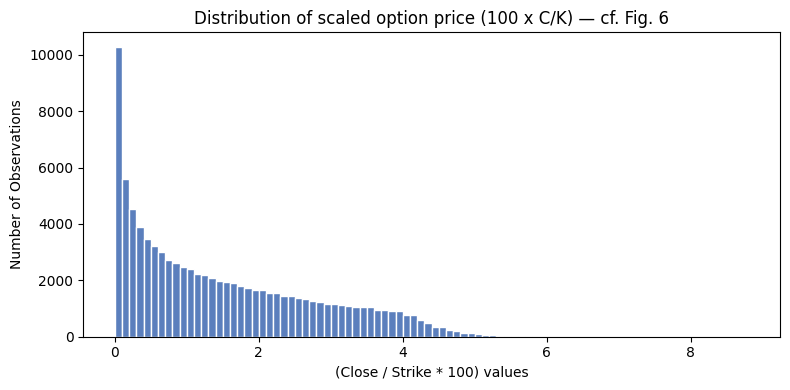

In [11]:
BIN_WIDTH = 0.1
NUM_CLASSES = 50   # ANN output layer = 50 neurons (softmax)

opt['output_ratio'] = 100 * opt['close'] / opt['strike']
opt['bin_label_raw'] = np.ceil(opt['output_ratio'] / BIN_WIDTH).astype(int)
opt['bin_label'] = np.clip(opt['bin_label_raw'], 1, NUM_CLASSES)

plt.figure(figsize=(8, 4))
plt.hist(opt['output_ratio'], bins=np.arange(0, opt['output_ratio'].max() + BIN_WIDTH, BIN_WIDTH),
         color='#5b7fbd', edgecolor='white')
plt.xlabel('(Close / Strike * 100) values')
plt.ylabel('Number of Observations')
plt.title('Distribution of scaled option price (100 x C/K) — cf. Fig. 6')
plt.tight_layout()
plt.show()

## 5. Feature sets — Approach I, II, III

**Log returns.** For a time series $S$, $LR(S)_i = \log(S_i) - \log(S_{i-1})$
(Eq. 3), computed over the trailing 20-day window (→ 19 log returns).

**Approach I (22 features):**
19 order statistics of the log returns of the underlying's Close +
time-to-maturity + interest rate + moneyness (S/K).

**Approach II (17 features):**
Means of the log returns of Open/High/Low/Close (4) + 10 signed-square-root
covariance-matrix entries + moneyness + time-to-maturity + interest rate.

**Approach III (19 features):**
All of Approach II (17) + previous option price scaled ($C_{t-1}/K$) +
mean moneyness ($\bar S / K$ over the 20-day window).

In [12]:
def log_returns_from_lookback(df, field):
    cols_chrono = [f'und_{field}_lag{i}' for i in range(20, 0, -1)]   # oldest -> newest
    prices = df[cols_chrono].values.astype(float)
    return np.diff(np.log(prices), axis=1)   # 19 log returns,

lr_close = log_returns_from_lookback(opt, 'close')
lr_open  = log_returns_from_lookback(opt, 'open')
lr_high  = log_returns_from_lookback(opt, 'high')
lr_low   = log_returns_from_lookback(opt, 'low')

In [13]:
#19 order statistics + moneyness + TTM + interest rate ----
order_stats_close = np.sort(lr_close, axis=1)

approach1 = pd.DataFrame(order_stats_close, columns=[f'os_close_{i+1}' for i in range(19)], index=opt.index)
approach1['moneyness']         = opt['underlying'] / opt['strike']
approach1['time_to_maturity']  = opt['days_to_expiry']
approach1['interest_rate']     = opt['risk_free_rate']
approach1['bin_label']         = opt['bin_label']

assert approach1.shape[1] - 1 == 22, "Approach I must have exactly 22 features"
print("Approach I feature count (excl. label):", approach1.shape[1] - 1)

Approach I feature count (excl. label): 22


In [14]:
#  means + signed-sqrt covariance + moneyness + TTM + interest rate ----
mu_O = lr_open.mean(axis=1); mu_H = lr_high.mean(axis=1)
mu_L = lr_low.mean(axis=1);  mu_C = lr_close.mean(axis=1)

stack = np.stack([lr_open, lr_high, lr_low, lr_close], axis=1)          # (n, 4, 19)
centered = stack - stack.mean(axis=2, keepdims=True)
cov = np.einsum('nik,njk->nij', centered, centered) / (stack.shape[2] - 1)   # (n, 4, 4)

def signed_sqrt(x):
    out = np.zeros_like(x)
    mask = x != 0
    out[mask] = x[mask] / np.sqrt(np.abs(x[mask]))    # convention x/sqrt|x| = 0 iff x = 0
    return out

cov_transformed = signed_sqrt(cov)
idx_pairs = [(i, j) for i in range(4) for j in range(i + 1)]     # lower-triangular, 10 entries
labels = ['O', 'H', 'L', 'C']
cov_cols = {f'cov_{labels[i]}{labels[j]}': cov_transformed[:, i, j] for i, j in idx_pairs}

approach2 = pd.DataFrame({'mu_O': mu_O, 'mu_H': mu_H, 'mu_L': mu_L, 'mu_C': mu_C, **cov_cols}, index=opt.index)
approach2['moneyness']        = opt['underlying'] / opt['strike']
approach2['time_to_maturity'] = opt['days_to_expiry']
approach2['interest_rate']    = opt['risk_free_rate']
approach2['bin_label']        = opt['bin_label']

assert approach2.shape[1] - 1 == 17, "Approach II must have exactly 17 features"
print("Approach II feature count (excl. label):", approach2.shape[1] - 1)

Approach II feature count (excl. label): 17


In [15]:
#  Approach II + previous option price (scaled) + mean moneyness ----
approach3 = approach2.drop(columns=['bin_label']).copy()
approach3['prev_option_price_scaled'] = opt['prev_day_close'] / opt['strike']

lookback_close_cols = [f'und_close_lag{i}' for i in range(1, 21)]
mean_underlying_20d = opt[lookback_close_cols].mean(axis=1)
approach3['mean_moneyness'] = mean_underlying_20d / opt['strike']
approach3['bin_label'] = opt['bin_label']

assert approach3.shape[1] - 1 == 19, "Approach III must have exactly 19 features"
print("Approach III feature count (excl. label):", approach3.shape[1] - 1)

Approach III feature count (excl. label): 19


In [16]:
unique_dates = np.sort(opt['date'].unique())
cutoff_idx = int(len(unique_dates) * 0.70)
cutoff_date = unique_dates[cutoff_idx - 1]

train_mask = (opt['date'] <= cutoff_date).values
test_mask  = (opt['date'] >  cutoff_date).values

print(f"Train: {train_mask.sum()} rows (up to {pd.Timestamp(cutoff_date).date()})")
print(f"Test : {test_mask.sum()} rows (after {pd.Timestamp(cutoff_date).date()})")

Train: 57156 rows (up to 2025-06-06)
Test : 33018 rows (after 2025-06-06)


In [17]:
def error_metric_EM(actual_bins, predicted_bins, bin_width=BIN_WIDTH):
    """Eq. (5): EM = w/T * sum|C_i - P_i|"""
    return bin_width * np.mean(np.abs(actual_bins - predicted_bins))

def inaccuracy_metric_rho(actual_bins, predicted_bins):
    """Eq. (6): rho = fraction of predictions more than 2 bins away from the true bin"""
    return np.mean(np.abs(actual_bins - predicted_bins) > 2)

## 8. Models

**ANN :** Dense(128, ReLU) → Dense(64, ReLU) → Dense(50, softmax);
Adam optimizer, learning rate 0.00012, batch size 32, categorical cross-entropy loss.

**XGBoost:** `n_estimators=100`, `max_depth=3`, `learning_rate=0.3`,
multi-class softprob objective, categorical cross-entropy loss.




In [18]:
ANN_EPOCHS = 100  # not specified in the paper; fixed, not tuned/early-stopped

def train_ann(X_tr, y_tr_idx, num_classes, seed=RANDOM_SEED):
    tf.random.set_seed(seed)
    ann = keras.Sequential([
        keras.layers.Input(shape=(X_tr.shape[1],)),
        keras.layers.Dense(128, activation='relu'),   # Layer 1,
        keras.layers.Dense(64,  activation='relu'),   # Layer 2,
        keras.layers.Dense(num_classes, activation='softmax'),  # Layer 3,
    ])
    ann.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.00012),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    ann.fit(X_tr, y_tr_idx, epochs=ANN_EPOCHS, batch_size=32, verbose=0)
    return ann


def train_xgb(X_tr, y_tr_idx, num_classes, seed=RANDOM_SEED):
    dtrain = xgb.DMatrix(X_tr, label=y_tr_idx)
    xgb_params = {
        'objective': 'multi:softprob',
        'num_class': num_classes,
        'max_depth': 3,
        'learning_rate': 0.3,
        'eval_metric': 'mlogloss',
        'seed': seed,
    }
    booster = xgb.train(params=xgb_params, dtrain=dtrain, num_boost_round=100)  # Table A.1: n_estimators=100
    return booster

In [19]:
def train_and_evaluate(feature_df, approach_name, num_classes=NUM_CLASSES, seed=RANDOM_SEED):
    feature_cols = [c for c in feature_df.columns if c != 'bin_label']
    X_all = feature_df[feature_cols].values
    y_all = feature_df['bin_label'].values

    X_tr, X_te = X_all[train_mask], X_all[test_mask]
    y_tr, y_te = y_all[train_mask], y_all[test_mask]

    y_tr_idx = y_tr - 1   # xgboost/keras need zero-indexed class labels

    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s = scaler.transform(X_te)

    ann = train_ann(X_tr_s, y_tr_idx, num_classes, seed)
    booster = train_xgb(X_tr_s, y_tr_idx, num_classes, seed)

    ann_pred = ann.predict(X_te_s, verbose=0).argmax(axis=1) + 1
    xgb_pred = booster.predict(xgb.DMatrix(X_te_s)).argmax(axis=1) + 1
    ens_pred = (ann_pred + xgb_pred) / 2   #  simple average ensemble

    return {
        'approach':     approach_name,
        'ANN_EM':       error_metric_EM(y_te, ann_pred),
        'ANN_rho':      inaccuracy_metric_rho(y_te, ann_pred),
        'XGB_EM':       error_metric_EM(y_te, xgb_pred),
        'XGB_rho':      inaccuracy_metric_rho(y_te, xgb_pred),
        'Ensemble_EM':  error_metric_EM(y_te, ens_pred),
        'Ensemble_rho': inaccuracy_metric_rho(y_te, ens_pred),
    }

In [20]:
results_list = [
    train_and_evaluate(approach1, 'Approach I'),
    train_and_evaluate(approach2, 'Approach II'),
    train_and_evaluate(approach3, 'Approach III'),
]
results_df = pd.DataFrame(results_list).set_index('approach').round(3)

em_table  = results_df[['ANN_EM', 'XGB_EM', 'Ensemble_EM']].rename(columns=lambda c: c.replace('_EM', ''))
rho_table = results_df[['ANN_rho', 'XGB_rho', 'Ensemble_rho']].rename(columns=lambda c: c.replace('_rho', ''))

print("=== EM (lower is better) — cf. Table 4/5 ===")
print(em_table)
print("\n=== rho (lower is better) — cf. Table 4/5 ===")
print(rho_table)

=== EM (lower is better) — cf. Table 4/5 ===
                ANN    XGB  Ensemble
approach                            
Approach I    0.168  0.154     0.143
Approach II   0.145  0.149     0.135
Approach III  0.127  0.129     0.117

=== rho (lower is better) — cf. Table 4/5 ===
                ANN    XGB  Ensemble
approach                            
Approach I    0.228  0.206     0.209
Approach II   0.184  0.194     0.191
Approach III  0.150  0.156     0.155


## 9. Black–Scholes benchmark

*"We use the historical volatility values observed over a window of the past
20 trading days to compute the Black–Scholes price."* Annualised via
$\sigma_{ann} = \sigma_{daily} \sqrt{252}$, using the same 20-day close
log-return window already computed for Approach I.

In [21]:
def black_scholes_call(S, K, T, r, sigma):
    S, K, T, r, sigma = (np.asarray(x, dtype=float) for x in (S, K, T, r, sigma))
    T = np.clip(T, 1/365, None)
    sigma = np.clip(sigma, 1e-4, None)
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

opt['hist_vol'] = lr_close.std(axis=1, ddof=1) * np.sqrt(252)   # 20-day historical volatility, annualised

test_df = opt.loc[test_mask].copy()
test_df['bs_price'] = black_scholes_call(
    S=test_df['underlying'], K=test_df['strike'], T=test_df['time_to_maturity_yrs'],
    r=test_df['risk_free_rate'] / 100, sigma=test_df['hist_vol'],
)
test_df['bs_output_ratio'] = 100 * test_df['bs_price'] / test_df['strike']

bs_bin = np.clip(np.ceil(test_df['bs_output_ratio'] / BIN_WIDTH).astype(int), 1, NUM_CLASSES)
actual_bin_test = test_df['bin_label'].values

bs_EM  = error_metric_EM(actual_bin_test, bs_bin.values)
bs_rho = inaccuracy_metric_rho(actual_bin_test, bs_bin.values)

print(f"Black-Scholes -> EM: {bs_EM:.3f}, rho: {bs_rho:.3f}")

Black-Scholes -> EM: 0.247, rho: 0.344


In [22]:
summary_em = pd.concat([
    pd.DataFrame({'ANN': [bs_EM], 'XGB': [bs_EM], 'Ensemble': [bs_EM]}, index=['B-S pricing']),
    em_table
]).round(3)

summary_rho = pd.concat([
    pd.DataFrame({'ANN': [bs_rho], 'XGB': [bs_rho], 'Ensemble': [bs_rho]}, index=['B-S pricing']),
    rho_table
]).round(3)

print("=== EM ===")
print(summary_em)
print("\n=== rho ===")
print(summary_rho)

=== EM ===
                ANN    XGB  Ensemble
B-S pricing   0.247  0.247     0.247
Approach I    0.168  0.154     0.143
Approach II   0.145  0.149     0.135
Approach III  0.127  0.129     0.117

=== rho ===
                ANN    XGB  Ensemble
B-S pricing   0.344  0.344     0.344
Approach I    0.228  0.206     0.209
Approach II   0.184  0.194     0.191
Approach III  0.150  0.156     0.155
